# Projet Embedded Security — trouver le 1er caractère

Objectif minimal : retrouver **uniquement le premier caractère** du mot de passe.

Idée : la pin 13 de l'Arduino reste haute pendant la vérification, et la vérification
s'arrête au premier caractère faux. Donc le bon premier caractère fait durer la
vérification plus longtemps → trace de puissance plus « active ». On teste chaque
caractère candidat et on garde celui qui donne la plus grande activité.

(Indice du wiki : le premier caractère est `f` — on vérifie si on le retrouve.)


## 1. Mettre le STM32 interne du Nano en haute impédance

À lancer **une fois** pour que le STM32 embarqué ne perturbe pas les mesures de l'Arduino.


In [ ]:
import os
import chipwhisperer as cw

FW_DIR  = r"C:\Users\felix\ChipWhispererSCA101\chipwhisperer\firmware\mcu\stm32-gpio-tristate"
fw_path = os.path.join(FW_DIR, "gpio-tristate-CWNANO.hex")

if "scope" in globals():
    scope.dis()

scope = cw.scope()
cw.program_target(scope, cw.programmers.STM32FProgrammer, fw_path)
scope.dis()
print("STM32 interne en haute impedance. OK.")

Detected known STMF32: STM32F04xxx
Extended erase (0x44), this can take ten seconds or more


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\felix\\ChipWhispererSCA101\\chipwhisperer\\firmware\\mcu\\stm32-gpio-tristate\\gpio-tristate-CWNANO.hex'

: 

## 2. Connexion et fonction de capture

Câblage : pin 2=GND, pin 8=5V, pin 10=RX, pin 12=TX, **GPIO4 (trigger) = pin 13**.

`capture_guess` envoie une tentative et renvoie la trace capturée pendant la vérification.
On arme **avant** d'écrire pour ne pas rater le front montant de pin 13 (le trigger).

In [ ]:
import numpy as np
import chipwhisperer as cw

if "scope" in globals():
    scope.dis()

scope = cw.scope()
scope.default_setup()          # 7.5 MHz ADC, 5000 echantillons
target = cw.target(scope, cw.targets.SimpleSerial2)
target.baud = 9600

def resync(timeout=400):
    """Vide tout le backlog et attend que l'ATmega soit de nouveau en attente
    d'une ligne (etat aligne). A appeler une fois avant une campagne de captures."""
    target.ser.flush()
    while target.ser.read(200, timeout=timeout):   # lit jusqu'a un silence
        pass
    target.ser.flush()

def capture_guess(guess):
    """Envoie 'guess\\n', capture la trace PENDANT la verif (trigger pin 13),
    PUIS lit la reponse pour rester synchronise : 1 tentative = 1 ligne traitee.
    C'est ce drain de la reponse qui empeche la desynchronisation."""
    scope.arm()
    target.ser.write((guess + "\n").encode("latin-1"))
    timed_out = scope.capture()                     # attend pin 13 (notre tentative)
    target.ser.read(100, timeout=120)               # draine ">> ACCESS DENIED...Enter password:"
    if timed_out:
        return None
    return scope.get_last_trace()

resync()
print("Connecte + synchronise.")
# verif rapide d'alignement : on doit retomber sur une trace valide
_t = capture_guess("f")
print("capture test:", None if _t is None else ("OK, %d samples" % len(_t)))

Connecte + synchronise.
capture test: OK, 5000 samples


In [ ]:
# === VERIFICATION : le test de mot de passe part-il bien, et l'ATmega repond-il ? ===

# 1) on vide la reception
try:
    pending = target.ser.in_waiting() or 0
    if pending:
        print("octets en attente avant envoi :", repr(target.ser.read(pending)))
except Exception as e:
    print("in_waiting indisponible :", e)

# 2) on envoie une tentative en surveillant le trigger (pin 13)
essai = "f\n"
scope.arm()
target.ser.write(essai.encode("latin-1"))
timed_out = scope.capture()
print("Tentative envoyee :", repr(essai))
print("Trigger declenche (pin 13 montee) ?", "OUI" if not timed_out else "NON (timeout)")

# 3) on lit ce que l'ATmega renvoie
import time
time.sleep(0.1)
resp = target.ser.read(200)
print("Reponse brute du target :", repr(resp))
print("Longueur reponse :", len(resp) if resp else 0)

# --- interpretation ---
if not resp:
    print("\n>> Rien recu. Causes probables : TX/RX non croises, mauvais baud,")
    print("   ou l'ATmega n'ecoute pas sur cette UART.")
elif timed_out:
    print("\n>> Le target repond mais pin 13 ne declenche pas : verifie pin 13 -> GPIO4.")
else:
    print("\n>> Communication OK : l'ATmega recoit la tentative ET pin 13 declenche.")

in_waiting indisponible : 'SimpleSerial_ChipWhispererLite' object has no attribute 'in_waiting'
Tentative envoyee : 'f\n'
Trigger declenche (pin 13 montee) ? OUI
Reponse brute du target : '>> ACCESS DENIED\r\n\r\nEnter password:\r\n'
Longueur reponse : 37

>> Communication OK : l'ATmega recoit la tentative ET pin 13 declenche.


## 3. Tester chaque caractère — analyse de **puissance** (pas de temps)

On ne mesure plus la *durée* de la vérification. On exploite l'**amplitude** de la
consommation à l'instant précis où la puce compare notre caractère au bon.

Méthode :
1. trace moyennée pour chaque candidat `!`..`~` ;
2. à chaque instant, on regarde de combien chaque candidat s'écarte de la consommation
   « typique » (moyenne de tous les candidats) ;
3. l'**instant de fuite** = l'échantillon où un candidat s'écarte le plus du groupe ;
4. à cet instant, le candidat dont la **puissance** est la plus différente = le bon caractère.

C'est de la SPA : la comparaison correcte produit une signature de puissance distincte,
localisée dans le temps.

Instant de fuite (echantillon): 1692
Top 10 par amplitude de fuite de PUISSANCE a cet instant:
  'f' : 0.2441
  '%' : 0.0696
  '!' : 0.0622
  '(' : 0.0614
  'H' : 0.0605
  'W' : 0.0527
  'V' : 0.0516
  'G' : 0.0503
  '$' : 0.0497
  '*' : 0.0462

>>> 1er caractere le plus probable (puissance): 'f'
    ('f' est classe #1 sur 94)


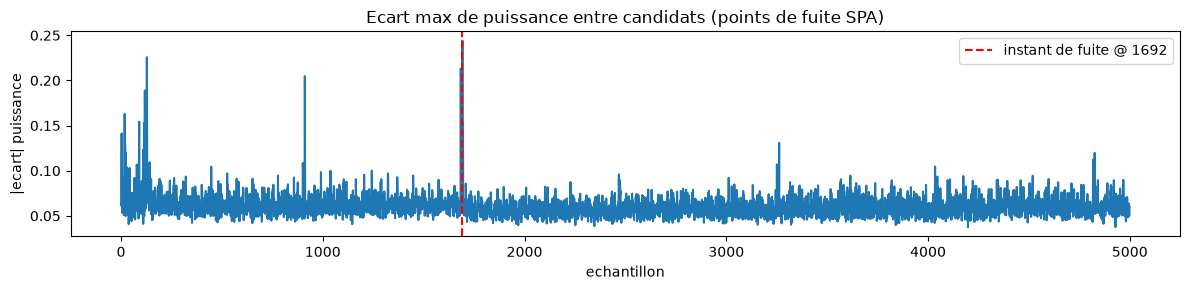

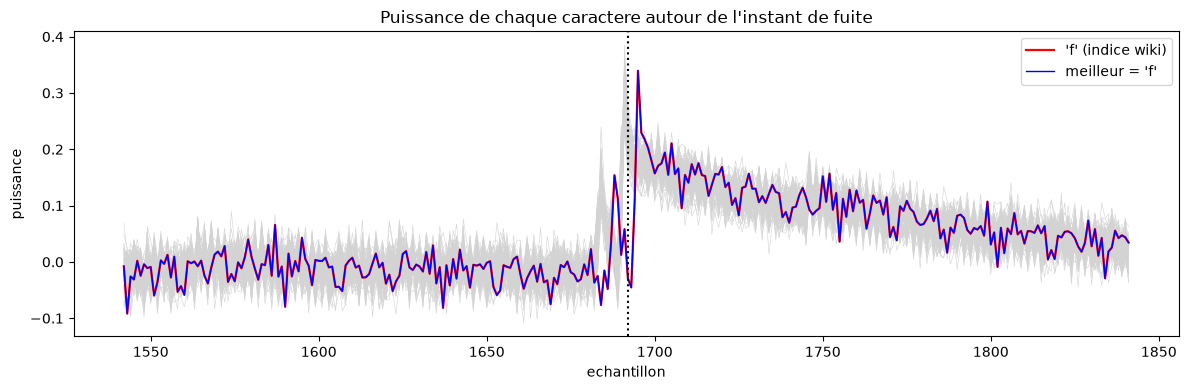

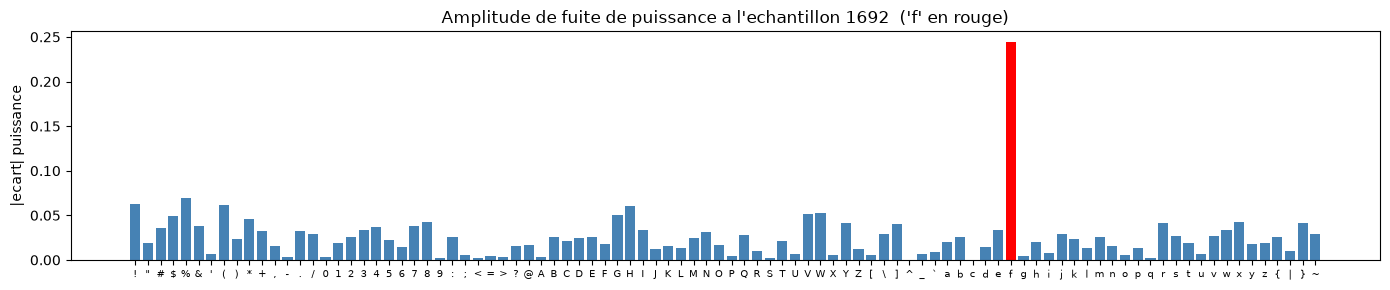

In [ ]:
import matplotlib.pyplot as plt

N_REPEAT = 10   # captures moyennees par caractere (monte a 20-30 si bruite)

resync()        # on repart d'un etat aligne

# 1) trace de PUISSANCE moyennee pour chaque caractere candidat
traces = {}
for c in range(33, 127):
    ch = chr(c)
    acc = [tr for tr in (capture_guess(ch) for _ in range(N_REPEAT)) if tr is not None]
    if acc:
        traces[ch] = np.mean(acc, axis=0)

chars = sorted(traces)                          # caracteres effectivement captures
M = np.vstack([traces[ch] for ch in chars])     # matrice (n_car x n_echantillons)

# 2) a chaque instant : ecart de chaque candidat vs la consommation "typique"
mu = M.mean(axis=0)                             # puissance moyenne (tous candidats) par instant
D  = M - mu                                     # ecart de puissance de chaque candidat

# 3) instant de fuite = ou un candidat s'ecarte le plus du groupe
spread  = np.max(np.abs(D), axis=0)             # ecart max entre candidats, instant par instant
t_star  = int(np.argmax(spread))

# 4) a cet instant, le candidat le plus ecarte = caractere correct (fuite de puissance)
score = np.abs(D[:, t_star])
ordre = np.argsort(score)[::-1]
best  = chars[ordre[0]]

print("Instant de fuite (echantillon):", t_star)
print("Top 10 par amplitude de fuite de PUISSANCE a cet instant:")
for i in ordre[:10]:
    print(f"  {chars[i]!r} : {score[i]:.4f}")
print("\n>>> 1er caractere le plus probable (puissance):", repr(best))
if "f" in chars:
    rang_f = list(ordre).index(chars.index("f")) + 1
    print(f"    ('f' est classe #{rang_f} sur {len(chars)})")

# --- Plot 1 : ou ca fuit (ecart max entre candidats a chaque instant) ---
plt.figure(figsize=(12, 3))
plt.plot(spread)
plt.axvline(t_star, color="red", ls="--", label="instant de fuite @ {}".format(t_star))
plt.title("Ecart max de puissance entre candidats (points de fuite SPA)")
plt.xlabel("echantillon"); plt.ylabel("|ecart| puissance"); plt.legend(); plt.tight_layout(); plt.show()

# --- Plot 2 : puissance de chaque candidat, zoom autour de l'instant de fuite ---
a, b = max(0, t_star - 150), min(M.shape[1], t_star + 150)
plt.figure(figsize=(12, 4))
for ch in chars:
    plt.plot(range(a, b), traces[ch][a:b], color="lightgray", linewidth=0.4)
if "f" in traces:
    plt.plot(range(a, b), traces["f"][a:b], color="red", linewidth=1.6, label="'f' (indice wiki)")
plt.plot(range(a, b), traces[best][a:b], color="blue", linewidth=1.0, label="meilleur = {!r}".format(best))
plt.axvline(t_star, color="k", ls=":")
plt.title("Puissance de chaque caractere autour de l'instant de fuite")
plt.xlabel("echantillon"); plt.ylabel("puissance"); plt.legend(); plt.tight_layout(); plt.show()

# --- Plot 3 : amplitude de fuite par caractere (barres) ---
colors = ["red" if ch == "f" else "steelblue" for ch in chars]
plt.figure(figsize=(14, 3))
plt.bar(range(len(chars)), score, color=colors)
plt.xticks(range(len(chars)), chars, fontsize=7)
plt.title("Amplitude de fuite de puissance a l'echantillon {}  ('f' en rouge)".format(t_star))
plt.ylabel("|ecart| puissance"); plt.tight_layout(); plt.show()

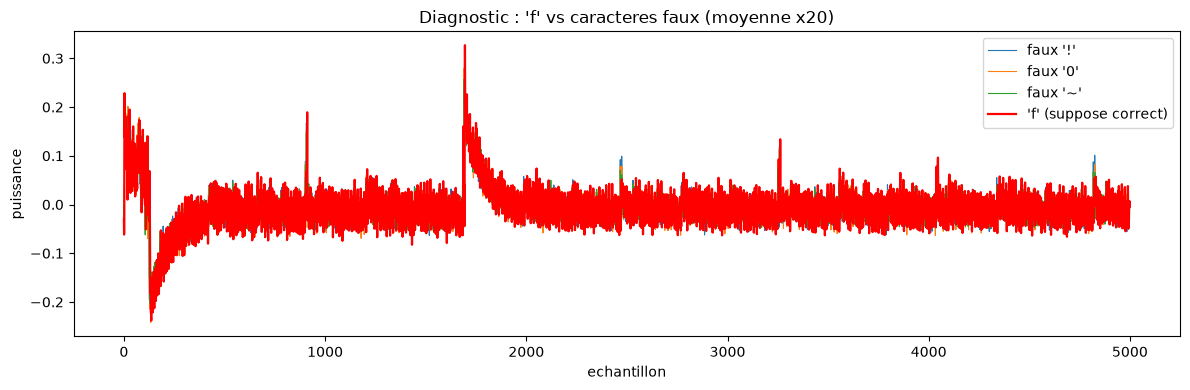

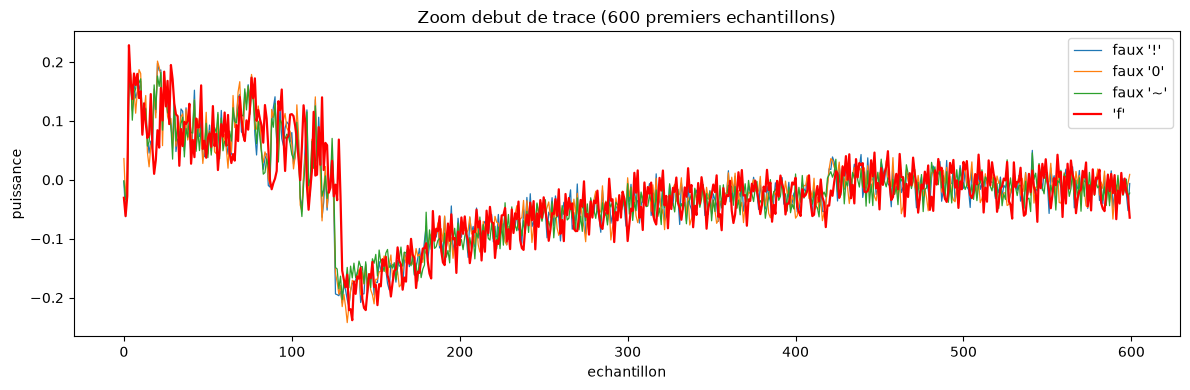

Divergence max a l'echantillon 128 valeur 0.27


In [ ]:
# === DIAGNOSTIC : la difference bon/mauvais 1er caractere est-elle visible ? ===
# On compare 'f' (suppose correct) a des caracteres surement faux, trace TRES moyennee.
import matplotlib.pyplot as plt

def trace_moyenne(ch, n=20):
    acc = [tr for tr in (capture_guess(ch) for _ in range(n)) if tr is not None]
    return np.mean(acc, axis=0) if acc else None

faux_chars = ["!", "0", "~"]
bon  = trace_moyenne("f", 20)
faux = {ch: trace_moyenne(ch, 20) for ch in faux_chars}

# Vue complete
plt.figure(figsize=(12, 4))
for ch, tr in faux.items():
    if tr is not None:
        plt.plot(tr, linewidth=0.8, label="faux '%s'" % ch)
if bon is not None:
    plt.plot(bon, color="red", linewidth=1.6, label="'f' (suppose correct)")
plt.legend(); plt.title("Diagnostic : 'f' vs caracteres faux (moyenne x20)")
plt.xlabel("echantillon"); plt.ylabel("puissance"); plt.tight_layout(); plt.show()

# Zoom sur le debut, la ou se fait la comparaison
plt.figure(figsize=(12, 4))
for ch, tr in faux.items():
    if tr is not None:
        plt.plot(tr[:600], linewidth=0.9, label="faux '%s'" % ch)
if bon is not None:
    plt.plot(bon[:600], color="red", linewidth=1.6, label="'f'")
plt.legend(); plt.title("Zoom debut de trace (600 premiers echantillons)")
plt.xlabel("echantillon"); plt.ylabel("puissance"); plt.tight_layout(); plt.show()

# Ou 'f' et le faux divergent-ils ? (difference absolue moyennee)
if bon is not None and faux.get("!") is not None:
    diff = np.abs(bon - faux["!"])
    print("Divergence max a l'echantillon", int(np.argmax(diff)), "valeur", round(float(diff.max()), 2))